Импорт нужных библиотек

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

Таблицы

In [9]:
df = pd.read_csv("https://github.com/AI-is-out-there/check-your-biomed-datascience-skills-review/raw/refs/heads/dev/dataset/task1/train.csv")
df_new = pd.read_csv("https://github.com/AI-is-out-there/check-your-biomed-datascience-skills-review/raw/refs/heads/dev/dataset/task1/test_features.csv")

print("Обучающая таблица:", df.shape)
print("Таблица для прогноза:", df_new.shape)

df.head(10)

Обучающая таблица: (800, 19)
Таблица для прогноза: (200, 18)


,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,prediction,Статус_глюкозы,Доклинический_риск
0,1,41,1,24.24,81.04,113.19,62.54,50.65,4.595,4.65,NaN,NaN,1.379,115.52,0,165.8,0,0,0
1,4,53,0,19.84,73.44,119.75,71.59,48.15,4.431,5.08,2.268,2.022,1.467,93.39,0,248.1,0,0,0
2,5,53,1,24.28,82.06,127.07,70.34,56.73,4.997,5.04,2.459,1.325,0.967,88.41,0,230.5,0,0,0
3,6,60,1,25.19,91.89,116.98,82.00,34.98,5.491,5.00,3.700,0.722,1.505,91.06,1,132.5,1,0,0
4,7,59,1,24.45,84.07,129.12,82.70,46.42,6.456,4.80,3.960,1.406,2.274,89.74,1,177.4,1,2,0
5,9,52,0,24.23,88.04,109.08,68.30,40.78,6.355,5.18,3.083,1.239,0.632,106.13,0,158.1,0,2,0
6,10,42,1,28.42,87.85,103.55,65.27,38.28,4.822,5.13,3.184,NaN,0.827,110.71,0,165.8,0,0,0
7,11,62,0,23.57,86.26,122.19,80.54,41.66,4.409,5.43,3.096,1.828,1.113,99.12,0,165.8,0,0,0
8,12,53,1,23.22,87.65,125.62,62.94,62.68,4.065,5.75,2.761,1.616,1.587,96.82,0,252.3,0,0,0
9,13,40,1,20.11,83.87,115.88,60.09,55.79,4.378,5.04,2.074,1.424,0.799,105.59,0,233.9,0,0,0


In [10]:
label_cols = ["prediction", "Статус_глюкозы", "Доклинический_риск"]
cols = [c for c in df.columns if c != "patient_id" and c not in label_cols]

print("Признаков:", len(cols))
print(df["prediction"].value_counts().rename({0: "Низкий риск", 1: "Высокий риск"}))

Признаков: 15
prediction
Низкий риск     655
Высокий риск    145
Name: count, dtype: int64


Разделение


In [11]:
rand = 7
X_all, y_all = df[cols], df['prediction']

X_tr, X_rest, y_tr, y_rest = train_test_split(
    X_all, y_all, train_size=0.7, stratify=y_all, random_state=rand)
X_va, X_te, y_va, y_te = train_test_split(
    X_rest, y_rest, test_size=0.5, stratify=y_rest, random_state=rand)

for name, part in [('train', y_tr), ('val', y_va), ('test', y_te)]:
    print(f'{name:5}: {len(part)} пациентов, высокий риск {part.mean():.1%}')

train: 560 пациентов, высокий риск 18.0%
val  : 120 пациентов, высокий риск 18.3%
test : 120 пациентов, высокий риск 18.3%


Очистка данных


In [12]:
binary = [c for c in cols if set(df[c].dropna().unique()) <= {0, 1}]
numeric = [c for c in cols if c not in binary]

z_scores = (X_tr[numeric] - X_tr[numeric].mean()) / X_tr[numeric].std()
is_outlier = z_scores.abs().gt(3).any(axis=1)

print('Бинарные признаки (не проверяем):', binary)
print('Выбросов по признакам:')
print(z_scores.abs().gt(3).sum().loc[lambda s: s > 0])

X_tr, y_tr = X_tr[~is_outlier], y_tr[~is_outlier]
print("\nУбрано пациентов: " + str(is_outlier.sum()) + ", в train осталось: " + str({len(X_tr)}))

Бинарные признаки (не проверяем): ['Пол_мужской', 'Курение']
Выбросов по признакам:
ИМТ                              2
САД_мм_рт_ст                     1
Пульсовое_давление               1
Глюкоза_натощак_ммоль_л          1
ЛПВП_ммоль_л                     1
Триглицериды_ммоль_л             1
Физическая_активность_мин_нед    1
dtype: int64

Убрано пациентов: 8, в train осталось: {552}


Пропуски

In [13]:
print("Пропуски в train до заполнения:")
print(X_tr.isna().sum().loc[lambda s: s > 0])

means = X_tr.mean()
scaler = StandardScaler().fit(X_tr.fillna(means))

A_tr, A_va, A_te = scaler.transform(X_tr[cols].fillna(means)),scaler.transform(X_va[cols].fillna(means)), scaler.transform(X_te[cols].fillna(means))

print("\nПропусков после prepare:", int(np.isnan(A_tr).sum() + np.isnan(A_va).sum() + np.isnan(A_te).sum()))
print("train после масштаба: mean =", A_tr.mean().round(3), " std =", A_tr.std().round(3))

Пропуски в train до заполнения:
ЛПНП_ммоль_л            24
ЛПВП_ммоль_л            31
Триглицериды_ммоль_л    33
СКФ_мл_мин              30
dtype: int64

Пропусков после prepare: 0
train после масштаба: mean = -0.0  std = 1.0


Нейросеть


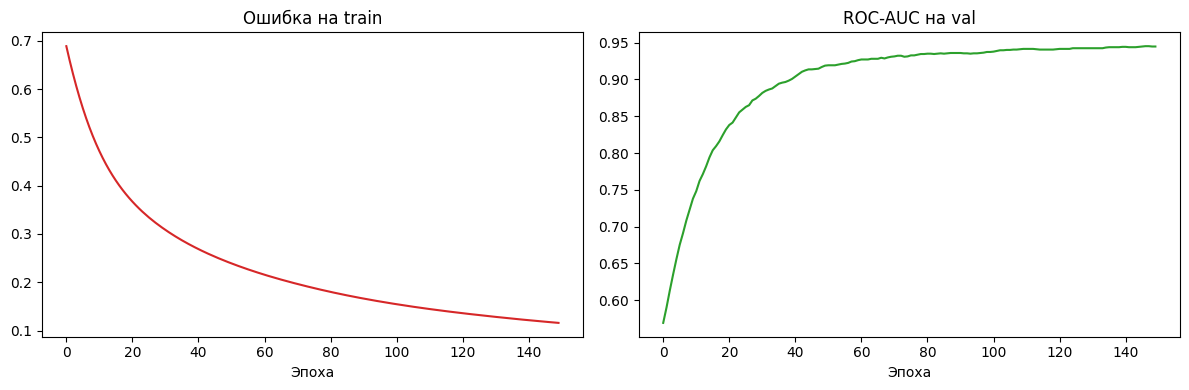

Эпоха 1:   loss 0.689, val ROC-AUC 0.569
Эпоха 150: loss 0.116, val ROC-AUC 0.945
Лучший val ROC-AUC: 0.945 на эпохе 147


In [14]:
net = MLPClassifier(hidden_layer_sizes=(32,), activation='relu', random_state=rand)

history = {'loss': [], 'val_auc': []}
for epoch in range(1, 151):
    net.partial_fit(A_tr, y_tr, classes=[0, 1])
    history['loss'].append(net.loss_)
    history['val_auc'].append(roc_auc_score(y_va, net.predict_proba(A_va)[:, 1]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history['loss'], color='tab:red')
ax1.set_xlabel('Эпоха')
ax1.set_title('Ошибка на train')

ax2.plot(history['val_auc'], color='tab:green')
ax2.set_xlabel('Эпоха')
ax2.set_title('ROC-AUC на val')

plt.tight_layout()
plt.show()

print(f"Эпоха 1:   loss {history['loss'][0]:.3f}, val ROC-AUC {history['val_auc'][0]:.3f}")
print(f"Эпоха 150: loss {history['loss'][-1]:.3f}, val ROC-AUC {history['val_auc'][-1]:.3f}")
print(f"Лучший val ROC-AUC: {max(history['val_auc']):.3f} на эпохе {int(np.argmax(history['val_auc'])) + 1}")

Отчёт по test

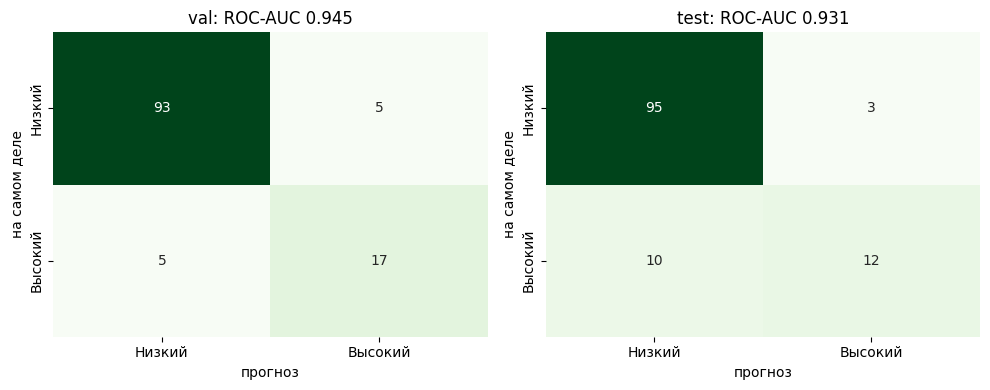

Отчёт по test:
              precision    recall  f1-score   support

      Низкий      0.905     0.969     0.936        98
     Высокий      0.800     0.545     0.649        22

    accuracy                          0.892       120
   macro avg      0.852     0.757     0.792       120
weighted avg      0.886     0.892     0.883       120



In [15]:
splits = [('val', A_va, y_va), ('test', A_te, y_te)]
labels = ['Низкий', 'Высокий']

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, A, y_true) in zip(axes, splits):
    y_hat = net.predict(A)
    y_prob = net.predict_proba(A)[:, 1]
    cm = confusion_matrix(y_true, y_hat)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(f'{name}: ROC-AUC {roc_auc_score(y_true, y_prob):.3f}')
    ax.set_xlabel('прогноз')
    ax.set_ylabel('на самом деле')

plt.tight_layout()
plt.show()

print('Отчёт по test:')
print(classification_report(y_te, net.predict(A_te), target_names=labels, digits=3))

Прогноз и сохранение

In [16]:
result = pd.DataFrame({
    "patient_id": df_new["patient_id"],
    "prediction": net.predict(scaler.transform(df_new[cols].fillna(means))),
})

os.makedirs("../outputs", exist_ok=True)
result.to_csv("../outputs/task1_predictions.csv", index=False)

assert len(result) == len(df_new) and result["patient_id"].equals(df_new["patient_id"])
assert result.notna().all().all()
print(result["prediction"].value_counts().rename({0: "Низкий риск", 1: "Высокий риск"}))

prediction
Низкий риск     172
Высокий риск     28
Name: count, dtype: int64


## Итог



*   Данные. 800 пациентов, 15 признаков; высокий риск — у 18%. Метки Статус_глюкозы и Доклинический_риск в признаки не включались.


*   Подготовка. Сначала разбиение 70/15/15, затем только на train: удаление 8 выбросов (|z| > 3), заполнение пропусков средним значением, StandardScaler.
*   Модель. MLP с одним скрытым слоем на 32 нейрона, активация ReLU, 150 эпох. Обучение шло стабильно, признаков переобучения нет.


*   Качество. ROC-AUC в диапазоне 0.93–0.95, specificity 0.97, однако доля найденных больных — лишь 55–77% (на test / val).
*   Что можно улучшить. Понизить порог с 0.5 или добавить веса классов — тогда пропущенных больных станет меньше, но вырастет число ложных тревог.















*   Ограничения. Данные синтетические. Модель может подсказать, кого стоит дообследовать, но окончательный диагноз остаётся за врачом.


